<a href="https://colab.research.google.com/github/MhiyaJ/My-GIS-Stuff/blob/main/CCHSDistrict_(PS3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **DO NOT RUN ALL!! WORK FROM 'STOP'**

IMPORTING PROGRAMS

Source: theaok.github.io/gisPy/, map.ipynb, Retrieved October 20, 2026

In [1]:
%%capture

import os, zipfile
import pandas as pd #
import matplotlib.pyplot as plt

import geopandas as gpd

import mapclassify

import seaborn as sns

import folium

from matplotlib.patches import Ellipse

from matplotlib.patheffects import withStroke

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files

from geopandas.tools import geocode

from google.colab.data_table import DataTable
DataTable.max_columns = 250

gpd.__version__

In [2]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Secondary_-5568767075062576326.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njrhs = gpd.read_file('School_Districts_Secondary.shp')

njhighschools.zip		School_Districts_Secondary.prj
sample_data			School_Districts_Secondary.shp
School_Districts_Secondary.cpg	School_Districts_Secondary.shp.xml
School_Districts_Secondary.dbf	School_Districts_Secondary.shx


In [3]:
njrhs.columns

Index(['NJDOE_ID_S', 'DIST_NAME', 'SCSDLEA', 'SD_TYPE', 'GEOID', 'geometry'], dtype='object')

In [4]:
njrhs.head(3)

,NJDOE_ID_S,DIST_NAME,SCSDLEA,SD_TYPE,GEOID,geometry
0,03-4300,Ramapo Indian Hills Regional High School District,13560,S,3413560,"POLYGON ((581460.48 800555.65, 581472.241 8005..."
1,19-3660,North Hunterdon-Voorhees Regional High School ...,11610,S,3411610,"POLYGON ((391770.815 705704.676, 392388.938 70..."
2,31-3980,Passaic County Manchester Regional High School...,12600,S,3412600,"POLYGON ((584057.82 765144.57, 584036.38 76509..."


In [5]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njrhs["NJDOE_ID_S"] = njrhs["NJDOE_ID_S"].astype(str)
njrhs[["CountyCode", "DistrictCode"]] = njrhs["NJDOE_ID_S"].str.extract(r"(\d{2}).*(\d{4})")

#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njrhs2 = njrhs[njrhs['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID', 'geometry']]
njrhs2['DistrictCode']=njrhs2.DistrictCode.str.strip()

njrhs2.rename(columns={'DIST_NAME' : 'District'}, inplace=True)
njrhs2['District'] = njrhs2['District'].str.upper()
njrhs2["District"] = njrhs2["District"].str.replace(" REGIONAL SCHOOL DISTRICT", "")

njrhs2

,DistrictCode,CountyCode,District,GEOID,geometry
20,5035,07,STERLING,3402880,"POLYGON ((342322.53 375467.11, 345610.5 373541..."
40,0390,07,BLACK HORSE PIKE,3401770,"POLYGON ((322014.45 380972.53, 321992.84 38092..."
42,1255,07,EASTERN CAMDEN COUNTY,3404380,"MULTIPOLYGON (((367503.372 354073.834, 370576...."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

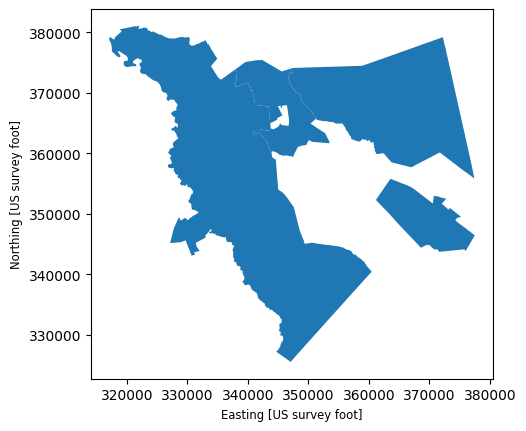

In [6]:
njrhs2.plot()

In [7]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Unified_7341673536716239500.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njsch = gpd.read_file('School_Districts_Unified.shp')

njhighschools.zip		    School_Districts_Secondary.shx
sample_data			    School_Districts_Unified.cpg
School_Districts_Secondary.cpg	    School_Districts_Unified.dbf
School_Districts_Secondary.dbf	    School_Districts_Unified.prj
School_Districts_Secondary.prj	    School_Districts_Unified.shp
School_Districts_Secondary.shp	    School_Districts_Unified.shp.xml
School_Districts_Secondary.shp.xml  School_Districts_Unified.shx


In [8]:
njsch.columns

Index(['NJDOE_ID_U', 'DIST_NAME', 'UNSDLEA', 'SD_TYPE', 'GEOID', 'geometry'], dtype='object')

In [9]:
njsch.head(5)

,NJDOE_ID_U,DIST_NAME,UNSDLEA,SD_TYPE,GEOID,geometry
0,05-5805,Willingboro Public School District,18000,U,3418000,"POLYGON ((386370.414 440959.026, 389173.931 44..."
1,23-4920,South River Public School District,15390,U,3415390,"POLYGON ((524300.577 593657.109, 524249.62 593..."
2,23-1170,East Brunswick Township School District,04110,U,3404110,"POLYGON ((526398.44 599176.69, 526588.81 59853..."
3,23-3290,Monroe Township School District,10500,U,3410500,"POLYGON ((520841.5 564988.81, 520860.72 564987..."
4,03-1130,Dumont Public School District,03990,U,3403990,"POLYGON ((636857.058 772962.29, 636946.462 772..."


In [10]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njsch["NJDOE_ID_U"] = njsch["NJDOE_ID_U"].astype(str)
njsch[["CountyCode", "DistrictCode"]] = njsch["NJDOE_ID_U"].str.extract(r"(\d{2}).*(\d{4})")

#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njsch2=njsch[njsch['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID','geometry']]
njsch2['DistrictCode']=njsch2.DistrictCode.str.strip()

njsch2.rename(columns={'DIST_NAME' : 'District'}, inplace=True)
njsch2['District'] = njsch2['District'].str.upper()
njsch2['District'] = njsch2['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
njsch2['District'] = njsch2['District'].str.replace("LAWNSIDE SCHOOL DISTRIC", "LAWNSIDE SCHOOL DISTRICT")
njsch2["District"] = njsch2["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
njsch2["District"] = njsch2["District"].str.replace(" SCHOOL DISTRICT", "")
njsch2["District"] = njsch2["District"].str.replace(" BOARD OF EDUCATION", "")

njsch2

,DistrictCode,CountyCode,District,GEOID,geometry
34,5820,07,WINSLOW TOWNSHIP,3418060,"POLYGON ((368609.977 344389.586, 368631.27 344..."
41,0150,07,AUDUBON,3401050,"POLYGON ((333599.519 389532.256, 334908.018 38..."
43,0940,07,COLLINGSWOOD,3403420,"POLYGON ((329936.77 398206.61, 330020.49 39819..."
50,1880,07,HADDON HEIGHTS,3406330,"POLYGON ((338431.442 383843.61, 338435.82 3836..."
51,2130,07,HI NELLA,3407080,"POLYGON ((346458.121 367972.644, 346568.817 36..."
52,3770,07,OAKLYN,3411940,"POLYGON ((331980.807 391389.812, 331778.88 391..."
53,0800,07,CHERRY HILL,3403000,"POLYGON ((347458.19 406942.14, 347464.79 40692..."
54,1900,07,HADDONFIELD,3406390,"POLYGON ((341402.77 394798.54, 341480.9 394783..."
58,4110,07,PINE HILL,3412990,"POLYGON ((351592.589 354425.759, 351577.79 351..."
59,1890,07,HADDON TOWNSHIP,3406360,"MULTIPOLYGON (((325315.69 389559.475, 325405.0..."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

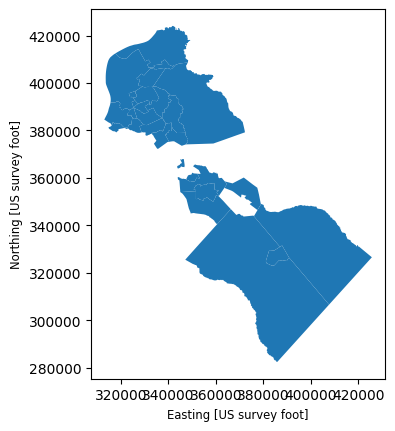

In [11]:
njsch2.plot()

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

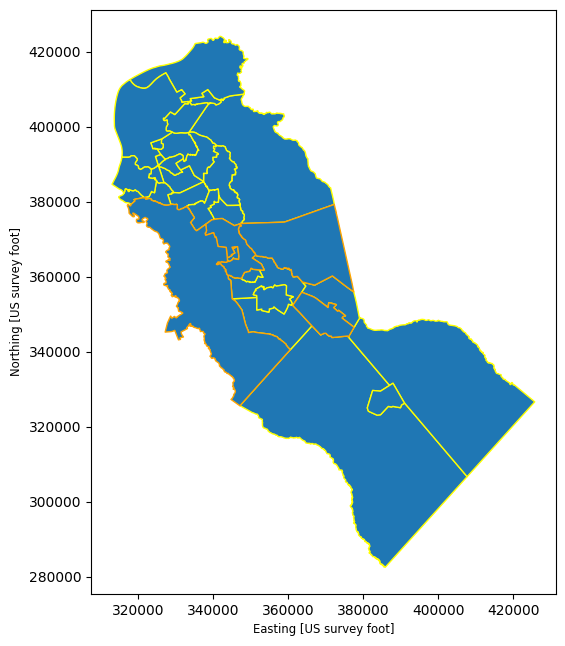

In [18]:
fig, ax = plt.subplots(1, figsize=(6,10))
njsch2.plot(ax=ax,edgecolor='yellow',linewidth=1)
njrhs2.plot (ax=ax, edgecolor='orange', linewidth=1)

In [12]:
!wget -q -O Muni.zip  https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Municipalities.zip
zip_ref = zipfile.ZipFile('Muni.zip', 'r');zip_ref.extractall(); zip_ref.close()

Muni = gpd.read_file('Municipalities.shp')

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, 'Municipalities Overlay with Camden County School Districts')

(np.float64(306938.36324177834),
 np.float64(431347.56424366427),
 np.float64(275407.80013244424),
 np.float64(431115.8274850424))

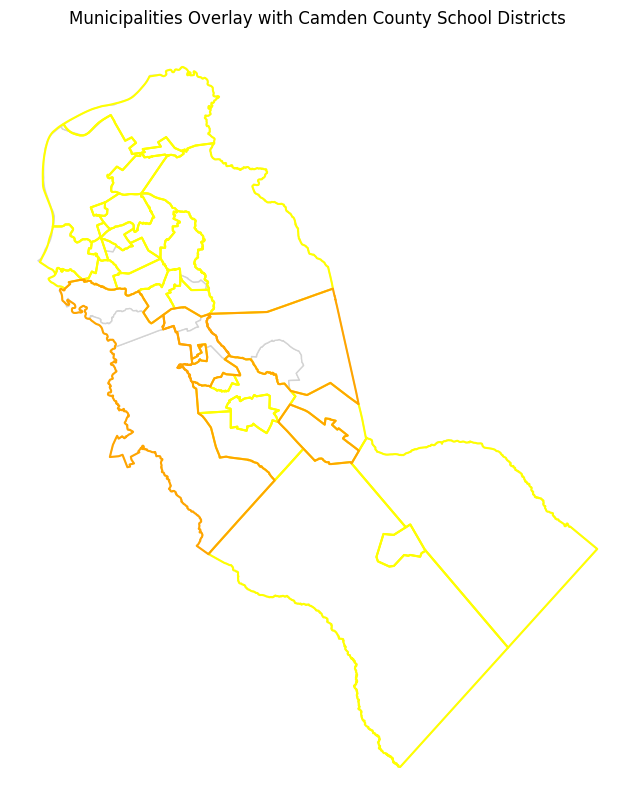

In [23]:
# Project the Muni shapefile to match the CRS of the school districts
Muni_proj = Muni.to_crs(njsch2.crs)

# Plot the layers together
fig, ax = plt.subplots(1, figsize=(10, 10))

# Plot Municipalities as the background layer
Muni_proj.plot(ax=ax, color='white', edgecolor='lightgray', linewidth=1, label='Municipalities')

# Overlay Unified and Secondary School Districts
njsch2.plot(ax=ax, color='none', edgecolor='yellow', linewidth=1.5, label='Unified School Districts')
njrhs2.plot(ax=ax, color='none', edgecolor='orange', linewidth=1.5, label='Secondary School Districts')

ax.set_title("Municipalities Overlay with Camden County School Districts")
ax.axis('off')
plt.show()

In [14]:
Muni.head()

,FID,COUSUBNS,GEOID,NAMELSAD,CLASSFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,GEOCODE,GlobalID,Shape__Are,Shape__Len,geometry
0,1,00885144,3400702200,Audubon borough,C5,F,3838781,35535,+39.8901277,-75.0723825,9407.757950,3400702200,81d661c6-35a7-42ed-8afd-5f35d0b0e807,3.871214e+06,9407.757866,"POLYGON ((495599.23 4415536.249, 495508.749 44..."
1,2,00885145,3400702230,Audubon Park borough,C5,F,389606,46935,+39.8968373,-75.0888190,2734.677596,3400702230,f8ccbea8-76dd-44e7-992b-e367d22e31a1,4.361934e+05,2734.677499,"POLYGON ((492866.221 4416337.872, 492855.687 4..."
2,3,00885149,3400703250,Barrington borough,C5,F,4095340,0,+39.8689349,-75.0513618,11456.984021,3400703250,9e9086b1-16e4-429f-b5c4-d967de1dbd82,4.092067e+06,11456.984073,"POLYGON ((496819.374 4414558.505, 496827.878 4..."
3,4,00885154,3400704750,Bellmawr borough,C5,F,7729295,315734,+39.8663560,-75.0946695,18085.471872,3400704750,bdd07346-3ee8-471e-befd-b8b9e16eb0a9,8.038608e+06,18085.472003,"POLYGON ((492951.896 4413667.751, 492968.147 4..."
4,5,00885158,3400705440,Berlin borough,C5,F,9307767,35573,+39.7920594,-74.9369855,14823.777678,3400705440,032f4608-e579-4343-a5e1-7d3778ce56c5,9.335884e+06,14823.777540,"POLYGON ((507881.319 4403761.193, 507873.371 4..."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

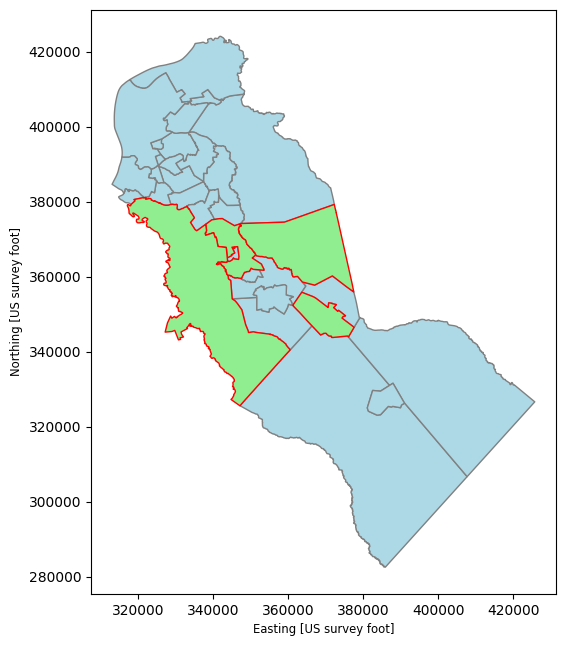

In [43]:
fig, ax = plt.subplots(1, figsize=(6,10))
njsch2.plot(ax=ax, edgecolor='grey', color = 'lightblue', linewidth=1)
njrhs2.plot(ax=ax, edgecolor='red', color = 'lightgreen', linewidth=1)

## **STOP STOP STOP STOP**

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

([Text(369870.4887486227, 315658.1276386258, 'WINSLOW TOWNSHIP'),
  Text(334572.81008224905, 386118.47739411145, 'AUDUBON'),
  Text(345166.53392647783, 395678.8632385152, 'COLLINGSWOOD'),
  Text(344829.40841847454, 380577.0366691216, 'HADDON HEIGHTS'),
  Text(340306.2623842831, 366211.8479671228, 'HI NELLA'),
  Text(330267.5177321778, 390312.2167352305, 'OAKLYN'),
  Text(363687.7715897786, 391125.67985588504, 'CHERRY HILL'),
  Text(346578.704193185, 389484.0202458709, 'HADDONFIELD'),
  Text(352431.7767036703, 346751.10340752313, 'PINE HILL'),
  Text(344423.9840021683, 393553.0453053487, 'HADDON TOWNSHIP'),
  Text(362421.8383605337, 357916.14672144235, 'LINDENWOLD'),
  Text(349944.1182078313, 376212.81011298264, 'LAWNSIDE'),
  Text(416097.89100208867, 332137.8608400872, 'WATERFORD TOWNSHIP'),
  Text(331103.55581069423, 376440.83797007153, 'BARRINGTON'),
  Text(325892.3575826529, 398151.9880982232, 'WOODLYNNE'),
  Text(340311.19720617717, 361444.60971774126, 'LAUREL SPRINGS'),
  Text(347

[]

[]

(np.float64(308456.66427294584),
 np.float64(430201.67503440706),
 np.float64(276823.57176200213),
 np.float64(429700.2905748793))

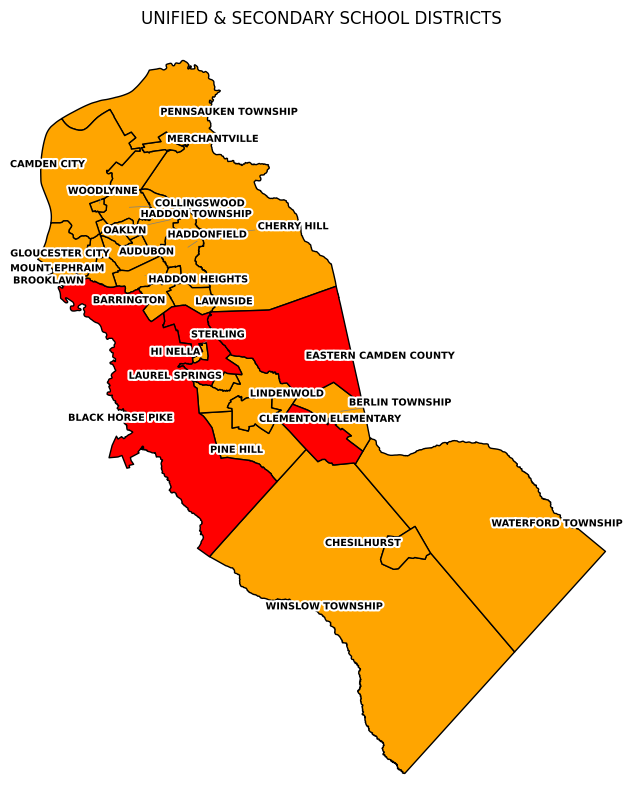

In [ ]:
fig, ax = plt.subplots(1, figsize=(10,10))
njsch2.plot(ax=ax, color='orange', edgecolor='black',linewidth=1)
njrhs2.plot(ax=ax, color='red', edgecolor='black',linewidth=1)

texts = []
for x, y, label in zip(njsch2.geometry.centroid.x, njsch2.geometry.centroid.y, njsch2.District):
       #Keep label names brief by stripping common suffixes to reduce overlap further
    display_label = label.replace(" Public School District", "").replace(" School District", "").replace(" Board Of Education", "")
    t = ax.text(x, y, display_label, fontsize=7, color='black', fontweight='bold',
                horizontalalignment='center', verticalalignment='center')
    t.set_path_effects([withStroke(linewidth=3, foreground='white')])
    texts.append(t)

for x, y, label in zip(njrhs2.geometry.centroid.x, njrhs2.geometry.centroid.y, njrhs2.District):
       #Keep label names brief by stripping common suffixes to reduce overlap further
    display_label = label.replace(" Public School District", "").replace(" School District", "").replace(" Board Of Education", "")
    t = ax.text(x, y, display_label, fontsize=7, color='black', fontweight='bold',
                horizontalalignment='center', verticalalignment='center')
    t.set_path_effects([withStroke(linewidth=3, foreground='white')])
    texts.append(t)

# Automatically resolve all overlaps
adjust_text(texts, arrowprops=dict(arrowstyle="-", color='gray', lw=0.5))

ax.title.set_text("UNIFIED & SECONDARY SCHOOL DISTRICTS")
ax.set_xticks([])
ax.set_yticks([])
ax.margins(0.04)
ax.axis("off")
plt.show()

In [ ]:
PrgXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/After%20School%20Programs.2.xlsx')

In [ ]:
PrgXls.head()

,After School Programs,Address,Unnamed: 2
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health


In [ ]:
#Rename columns and separated program types
PrgXls = PrgXls.rename(columns={'Unnamed: 2': 'Prog Type'})
PrgXls

,After School Programs,Address,Prog Type
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health
5,Collingswood Early Childhood Center,"201 Dayton Ave., Collingswood, NJ 08108",Health
6,Parkview Preschool,"700 W. Browning Rd., Collingswood, NJ 08107",Health
7,Oaklyn Public School,"136 Kendall Blvd., Oaklyn, NJ 08107",Health
8,"After-School All-Stars, Copewood Campus","1650 Copewood St., Camden, NJ 08103",General
9,"After-School All-Stars, Mt. Ephraim Campus","1575 Mt. Ephraim Ave., Camden, NJ 08104",General


In [ ]:
#Prompted Gemini to fix error due to length of after school program list

# Combine 'Address' and 'City' into a single string for better geocoding accuracy
full_addresses = PrgXls['Address'].astype(str) + ", New Jersey"

# Geocode using 'arcgis' provider to avoid Nominatim's strict 429 rate limiting
geo = geocode(full_addresses, provider='arcgis', timeout=10)
geo.head(3)

,geometry,address
0,POINT (-75.06635 39.9196),"265 Lincoln Ave, Collingswood, New Jersey, 08108"
1,POINT (-75.08938 39.91174),"400 Comly Ave, Oaklyn, New Jersey, 08107"
2,POINT (-75.07578 39.91817),"480 Haddon Ave, Collingswood, New Jersey, 08108"


In [ ]:
#PrgXls=gpd.GeoDataFrame(cchs,geometry='geometry'), didn't run therefore prompted Gemini to explain and fix error
# Assign the geocoded geometry to the main DataFrame
PrgXls['geometry'] = geo['geometry']

# Convert to a GeoDataFrame using the new geometry column
PrgXls = gpd.GeoDataFrame(PrgXls, geometry='geometry')

# End of Gemini assistance

#Strip to categorize
PrgFsc = PrgXls[PrgXls['Prog Type'].str.strip() == 'Family Success Center']
PrgCom = PrgXls[PrgXls['Prog Type'].str.strip() == 'Community Center']
PrgGen = PrgXls[PrgXls['Prog Type'].str.strip() == 'General']
PrgHea = PrgXls[PrgXls['Prog Type'].str.strip() == 'Health']

PrgXls.head(3)

,After School Programs,Address,Prog Type,geometry
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health,POINT (-75.06635 39.9196)
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health,POINT (-75.08938 39.91174)
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health,POINT (-75.07578 39.91817)


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

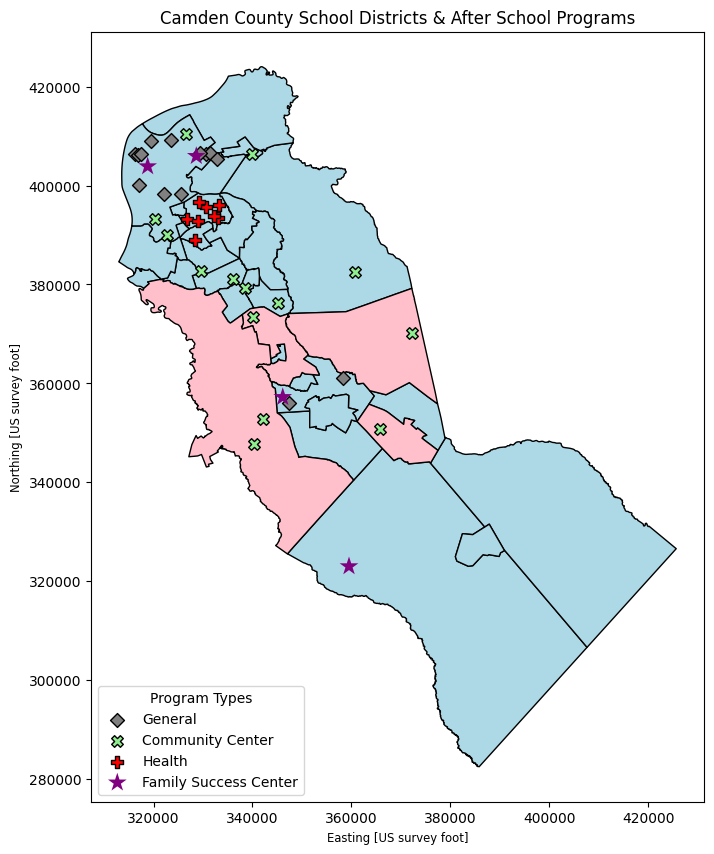

In [ ]:
# Project the program layers to match the coordinate reference system of the school districts
PrgGen_proj = PrgGen.to_crs(njsch2.crs)
PrgCom_proj = PrgCom.to_crs(njsch2.crs)
PrgHea_proj = PrgHea.to_crs(njsch2.crs)
PrgFsc_proj = PrgFsc.to_crs(njsch2.crs)

# Original run
fig, ax = plt.subplots(1, figsize=(10,10))

njsch2.plot(ax=ax, color='lightblue', edgecolor='black',linewidth=1)
njrhs2.plot(ax=ax, color='pink', edgecolor='black',linewidth=1)

# Prompted Gemini to create two legends
# Save the first legend (District Type) to prevent it from being overwritten
District_legend = ax.get_legend()

PrgGen_proj.plot(ax=ax, marker='D', color='grey', markersize=50, label='General', edgecolor='black')
PrgCom_proj.plot(ax=ax, marker='X', color='lightgreen', markersize=70, label='Community Center', edgecolor='black')
PrgHea_proj.plot(ax=ax, marker='P', color='red', markersize=70, label='Health', edgecolor='black')
PrgFsc_proj.plot(ax=ax, marker='*', color='purple', markersize=200, label='Family Success Center', edgecolor='none')

# Create the second legend (for Prog Type) on the lower left
Program_legend = ax.get_legend()

ax.legend(loc='lower left', title="Program Types")
# End of original run


# Add the first legend back to the axes manually so both are visible
if District_legend is not None:
    ax.add_artist(District_legend)

# End of Gemini prompts

ax.title.set_text("Camden County School Districts & After School Programs")

# Highlight ellipse (e.g. for Collingswood area)
ax = Ellipse(xy=(340000, 3930000), width=0.04, height=0.04, edgecolor='b', fc='None', lw=2.5)

#ax.axis('off')
plt.show()

In [ ]:
#Downloadable data regarding school performance
#https://www.nj.gov/education/spr/download/
DisXls=pd.read_excel ('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Economically%20Disadvantage%20Youth.xlsx', header = 3)

In [ ]:
##identify headings of Excel file
DisXls.head(3)

,CountyCode,CountyName,DistrictCode,Municpality,DistrictName,SchoolYear,Female,Male,Non-Binary/Undesignated Gender,Economically Disadvantaged Students,Students with Disabilities,Multilingual Learners,Students Experiencing Homelessness,Students in Foster Care,Military-Connected Students,Migrant Students
0,7,Camden,150,Audubon,Audubon Public School District,2020-21,49%,51%,<=1%,16.1%,21.9%,1.0%,0.5%,0.3%,1.1%,0%
1,7,Camden,150,Audubon,Audubon Public School District,2021-22,48%,52%,<=1%,17.6%,19.4%,1.0%,0.2%,0.4%,0.2%,0%
2,7,Camden,150,Audubon,Audubon Public School District,2022-23,48%,52%,<=1%,20.3%,19.8%,1.6%,0.9%,<0.1%,0.3%,0%


In [ ]:
#For School Year 2024-2025
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1 = DisXls[DisXls['SchoolYear'] =='2024-25'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1['DistrictName'] = DisXls1.DistrictName.str.strip()

DisXls1.rename(columns={'DistrictName' : 'District'}, inplace=True)
DisXls1['District'] = DisXls1['District'].str.upper()
DisXls1['District'] = DisXls1['District'].str.replace("MT. EPHRAIM", "MOUNT EPHRAIM")
DisXls1['District'] = DisXls1['District'].str.replace("LAWNSIDET", "LAWNSIDE")
DisXls1["District"] = DisXls1["District"].str.replace(" PUBLIC SCHOOL DISTRICT", "")
DisXls1["District"] = DisXls1["District"].str.replace(" REGIONAL", "")
DisXls1["District"] = DisXls1["District"].str.replace(" SCHOOL DISTRICT", "")
DisXls1["District"] = DisXls1["District"].str.replace(" BOARD OF EDUCATION", "")

# Format DistrictCode as a zero-padded 4-character string (e.g., 0150)
DisXls1['DistrictCode'] = DisXls1['DistrictCode'].apply(lambda x: f"{int(x):04d}" if pd.notnull(x) else x)

DisXls1

,CountyName,DistrictCode,District,Economically Disadvantaged Students
4,Camden,0150,AUDUBON,24.5%
9,Camden,0190,BARRINGTON,34.1%
14,Camden,0260,BELLMAWR,57.8%
19,Camden,0330,BERLIN BOROUGH,25.2%
24,Camden,0340,BERLIN TOWNSHIP,53.3%
29,Camden,0390,BLACK HORSE PIKE,44.9%
34,Camden,0580,BROOKLAWN,70.7%
39,Camden,0680,CAMDEN CITY,88.5%
44,Camden,0700,CAMDEN COUNTY TECHNICAL,56.1%
49,Camden,0800,CHERRY HILL,23.2%


In [ ]:
a1 = pd.merge(njsch2, DisXls1, left_on=['District'], right_on=['District'], how='outer', indicator=True)
a1.columns
a1[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,3401050,AUDUBON,Camden,0150,24.5%,both
1,3401170,BARRINGTON,Camden,0190,34.1%,both
2,NaN,BELLMAWR,Camden,0260,57.8%,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,25.2%,right_only
4,3401620,BERLIN TOWNSHIP,Camden,0340,53.3%,both
5,NaN,BLACK HORSE PIKE,Camden,0390,44.9%,right_only
6,3402370,BROOKLAWN,Camden,0580,70.7%,both
7,3402640,CAMDEN CITY,Camden,0680,88.5%,both
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,56.1%,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,91.2%,right_only


In [ ]:
a1._merge.value_counts()

,count
_merge,
both,23
right_only,19
left_only,2


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

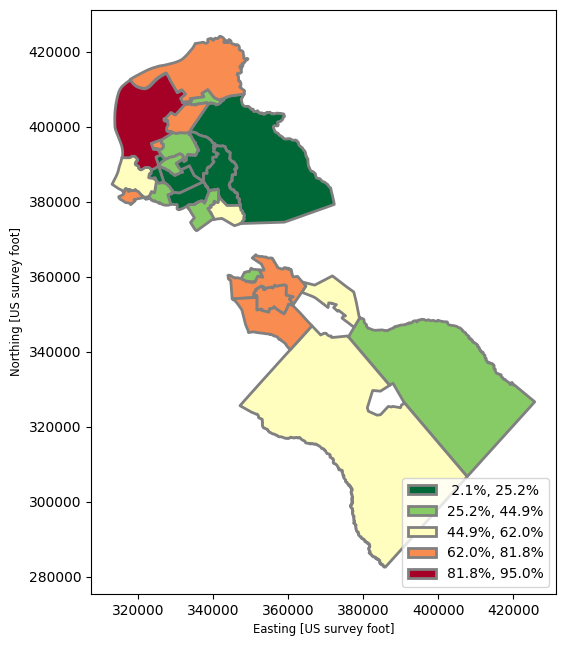

In [ ]:
# Clean and convert 'Economically Disadvantaged Students' to numeric values (e.g. 24.5 instead of '24.5%')
if a1['Economically Disadvantaged Students'].dtype == 'object':
    a1['Economically Disadvantaged Students'] = (
        a1['Economically Disadvantaged Students']
        .astype(str)
        .str.replace('%', '', regex=False)
        .str.strip()
    )
    a1['Economically Disadvantaged Students'] = pd.to_numeric(a1['Economically Disadvantaged Students'], errors='coerce')

# Plot the converted data
fig, ax = plt.subplots(1, figsize=(6,10))
a1.dropna(subset=['Economically Disadvantaged Students']).plot(
    ax=ax,
    column='Economically Disadvantaged Students',
    legend=True,
    cmap='RdYlGn_r',
    scheme='natural_breaks',
    k=5,
    edgecolor='grey',
    linewidth=2,
    legend_kwds={"fmt": "{:.1f}%", 'loc': 'lower right', 'markerscale': 1.4}
)

In [ ]:
a2 = pd.merge(njrhs2, DisXls1, left_on=['District'], right_on=['District'], how='outer', indicator=True)
a2.columns
a2[['GEOID','District','CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students', '_merge']]

Index(['DistrictCode_x', 'CountyCode', 'District', 'GEOID', 'geometry',
       'CountyName', 'DistrictCode_y', 'Economically Disadvantaged Students',
       '_merge'],
      dtype='object')

,GEOID,District,CountyName,DistrictCode_y,Economically Disadvantaged Students,_merge
0,NaN,AUDUBON,Camden,0150,24.5%,right_only
1,NaN,BARRINGTON,Camden,0190,34.1%,right_only
2,NaN,BELLMAWR,Camden,0260,57.8%,right_only
3,NaN,BERLIN BOROUGH,Camden,0330,25.2%,right_only
4,NaN,BERLIN TOWNSHIP,Camden,0340,53.3%,right_only
5,3401770,BLACK HORSE PIKE,Camden,0390,44.9%,both
6,NaN,BROOKLAWN,Camden,0580,70.7%,right_only
7,NaN,CAMDEN CITY,Camden,0680,88.5%,right_only
8,NaN,CAMDEN COUNTY TECHNICAL,Camden,0700,56.1%,right_only
9,NaN,"CAMDEN PREP, INC.",Camden,1801,91.2%,right_only


In [ ]:
a2._merge.value_counts()

,count
_merge,
right_only,39
both,3
left_only,0


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

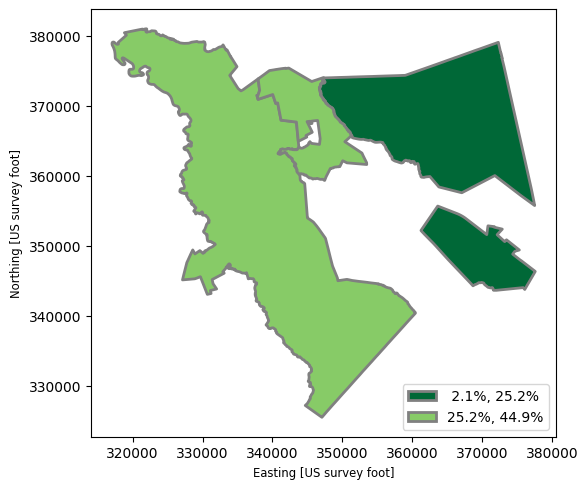

In [ ]:
# Clean and convert 'Economically Disadvantaged Students' to numeric values (e.g. 24.5 instead of '24.5%')
if a2['Economically Disadvantaged Students'].dtype == 'object':
    a2['Economically Disadvantaged Students'] = (
        a2['Economically Disadvantaged Students']
        .astype(str)
        .str.replace('%', '', regex=False)
        .str.strip()
    )
    a2['Economically Disadvantaged Students'] = pd.to_numeric(a2['Economically Disadvantaged Students'], errors='coerce')

# Plot the converted data
fig, ax = plt.subplots(1, figsize=(6,10))
a2.dropna(subset=['Economically Disadvantaged Students']).plot(
    ax=ax,
    column='Economically Disadvantaged Students',
    legend=True,
    cmap='RdYlGn_r',
    scheme='natural_breaks',
    k=5,
    edgecolor='grey',
    linewidth=2,
    legend_kwds={"fmt": "{:.1f}%", 'loc': 'lower right', 'markerscale': 1.4}
)

In [ ]:
#For School Year 2023-2024
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1=DisXls[DisXls['SchoolYear'] =='2023-24'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1['DistrictName']=DisXls1.DistrictName.str.strip()
DisXls1

,CountyName,DistrictCode,DistrictName,Economically Disadvantaged Students
3,Camden,150,Audubon Public School District,19.7%
8,Camden,190,Barrington School District,35.5%
13,Camden,260,Bellmawr Public School District,47.4%
18,Camden,330,Berlin Borough School District,17.2%
23,Camden,340,Berlin Township School District,36.4%
28,Camden,390,Black Horse Pike Regional School District,34.3%
33,Camden,580,Brooklawn Public School District,67.3%
38,Camden,680,Camden City School District,54.7%
43,Camden,700,Camden County Technical School District,50.2%
48,Camden,800,Cherry Hill School District,18.1%


In [ ]:
#For School Year 2022-2023
#Rename columns, only include 24-25 School Year, make upper case and strip white space, split Muni into first word only
DisXls1=DisXls[DisXls['SchoolYear'] =='2022-23'][['CountyName','DistrictCode','DistrictName','Economically Disadvantaged Students']]
DisXls1['DistrictName']=DisXls1.DistrictName.str.strip()
DisXls1

,CountyName,DistrictCode,DistrictName,Economically Disadvantaged Students
2,Camden,150,Audubon Public School District,20.3%
7,Camden,190,Barrington School District,25.9%
12,Camden,260,Bellmawr Public School District,43.9%
17,Camden,330,Berlin Borough School District,11.3%
22,Camden,340,Berlin Township School District,41.4%
27,Camden,390,Black Horse Pike Regional School District,31.3%
32,Camden,580,Brooklawn Public School District,65.0%
37,Camden,680,Camden City School District,54.5%
42,Camden,700,Camden County Technical School District,49.5%
47,Camden,800,Cherry Hill School District,18.8%


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2024 - 2025 School Year')

(np.float64(307329.39565478417),
 np.float64(431328.94365256873),
 np.float64(275408.0465878088),
 np.float64(431115.81574907264))

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2023 - 2024 School Year')

(np.float64(307329.39565478417),
 np.float64(431328.94365256873),
 np.float64(275408.0465878088),
 np.float64(431115.81574907264))

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

Text(0.5, 1.0, '% of Economically Disadvantaged Students\n2022 - 2023 School Year')

(np.float64(307329.39565478417),
 np.float64(431328.94365256873),
 np.float64(275408.0465878088),
 np.float64(431115.81574907264))

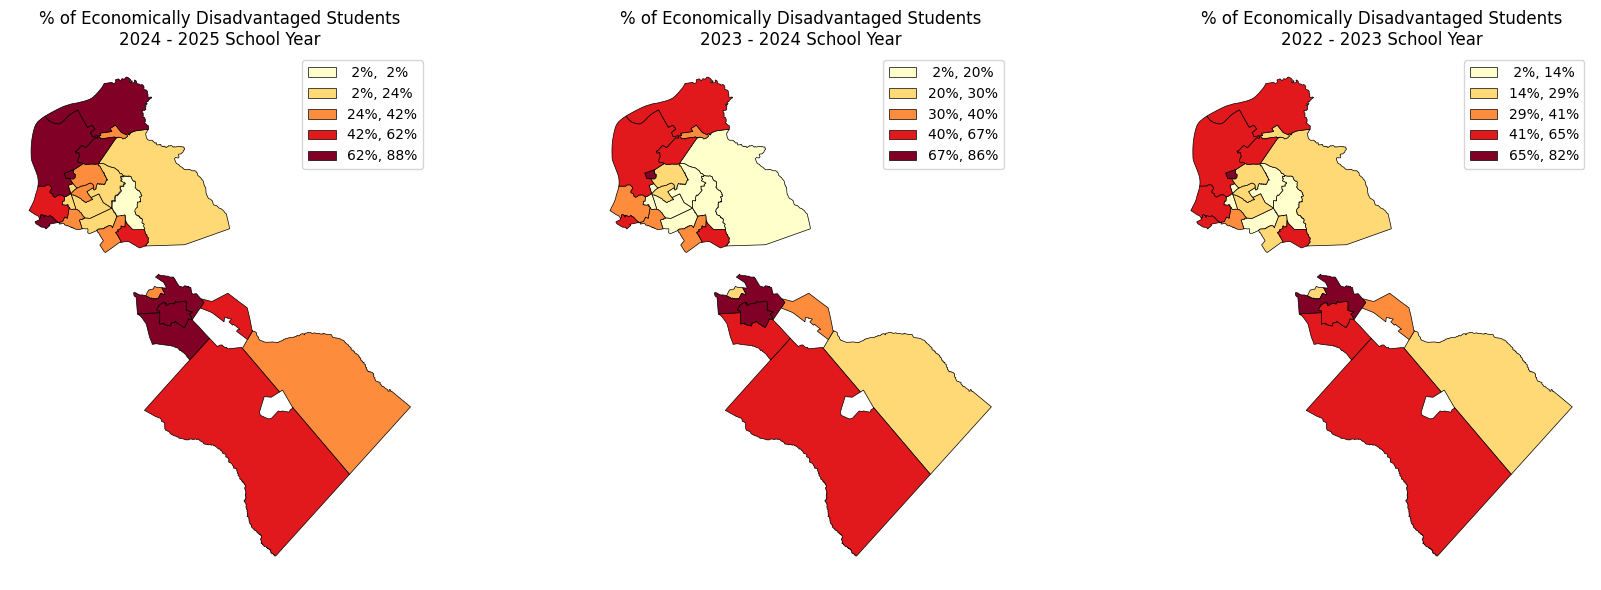

In [27]:
# 1. Load the school performance data first
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

DisXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/Economically%20Disadvantage%20Youth.xlsx', header=3)

# 2. Prepare school year datasets and clean names
# 2024-25
dis_24_25 = DisXls[DisXls['SchoolYear'] =='2024-25'][['DistrictCode','DistrictName','Economically Disadvantaged Students']].copy()
dis_24_25['DistrictName'] = dis_24_25['DistrictName'].str.strip().str.upper()
for term in ["MT. EPHRAIM", "LAWNSIDET", " PUBLIC SCHOOL DISTRICT", " REGIONAL", " SCHOOL DISTRICT", " BOARD OF EDUCATION"]:
    dis_24_25['DistrictName'] = dis_24_25['DistrictName'].str.replace(term, term.replace("MT. EPHRAIM", "MOUNT EPHRAIM").replace("LAWNSIDET", "LAWNSIDE") if "EPHRAIM" in term or "LAWNSIDET" in term else "", regex=False)

# 2023-24
dis_23_24 = DisXls[DisXls['SchoolYear'] =='2023-24'][['DistrictCode','DistrictName','Economically Disadvantaged Students']].copy()
dis_23_24['DistrictName'] = dis_23_24['DistrictName'].str.strip().str.upper()
for term in ["MT. EPHRAIM", "LAWNSIDET", " PUBLIC SCHOOL DISTRICT", " REGIONAL", " SCHOOL DISTRICT", " BOARD OF EDUCATION"]:
    dis_23_24['DistrictName'] = dis_23_24['DistrictName'].str.replace(term, term.replace("MT. EPHRAIM", "MOUNT EPHRAIM").replace("LAWNSIDET", "LAWNSIDE") if "EPHRAIM" in term or "LAWNSIDET" in term else "", regex=False)

# 2022-23
dis_22_23 = DisXls[DisXls['SchoolYear'] =='2022-23'][['DistrictCode','DistrictName','Economically Disadvantaged Students']].copy()
dis_22_23['DistrictName'] = dis_22_23['DistrictName'].str.strip().str.upper()
for term in ["MT. EPHRAIM", "LAWNSIDET", " PUBLIC SCHOOL DISTRICT", " REGIONAL", " SCHOOL DISTRICT", " BOARD OF EDUCATION"]:
    dis_22_23['DistrictName'] = dis_22_23['DistrictName'].str.replace(term, term.replace("MT. EPHRAIM", "MOUNT EPHRAIM").replace("LAWNSIDET", "LAWNSIDE") if "EPHRAIM" in term or "LAWNSIDET" in term else "", regex=False)

# 3. Merge with Unified School Districts shapefile (njsch2)
a6 = pd.merge(njsch2, dis_24_25, left_on='District', right_on='DistrictName', how='inner')
a7 = pd.merge(njsch2, dis_23_24, left_on='District', right_on='DistrictName', how='inner')
a8 = pd.merge(njsch2, dis_22_23, left_on='District', right_on='DistrictName', how='inner')

# 4. Clean percentage strings to float
for df in [a6, a7, a8]:
    if df['Economically Disadvantaged Students'].dtype == 'object':
        df['Economically Disadvantaged Students'] = df['Economically Disadvantaged Students'].astype(str).str.replace('%', '', regex=False).str.strip()
        df['Economically Disadvantaged Students'] = pd.to_numeric(df['Economically Disadvantaged Students'], errors='coerce')

# 5. Plot side-by-side comparison
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

a6.plot(ax=ax1, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax1.set_title('% of Economically Disadvantaged Students\n2024 - 2025 School Year')
ax1.axis('off')

a7.plot(ax=ax2, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax2.set_title('% of Economically Disadvantaged Students\n2023 - 2024 School Year')
ax2.axis('off')

a8.plot(ax=ax3, column='Economically Disadvantaged Students', legend=True, cmap='YlOrRd',
        scheme='natural_breaks', k=5, edgecolor='black', linewidth=.5, legend_kwds={"fmt": "{:.0f}%"})
ax3.set_title('% of Economically Disadvantaged Students\n2022 - 2023 School Year')
ax3.axis('off')

plt.tight_layout()
plt.show()